In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

print("\nFirst Five Rows:")
print(X.head())

print("\nDataset Description:")
print(X.describe())

print("\nTarget Classes:")
print(data.target_names)

print("\nMissing Values:")
print(X.isnull().sum().sum())

Dataset Shape: (569, 30)

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)

Training Target Shape: (455,)
Testing Target Shape: (114,)


In [3]:
log_model = LogisticRegression(max_iter=5000)
dt_model = DecisionTreeClassifier(random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)
svm_model = SVC(probability=True, random_state=42)

base_models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "SVM": svm_model
}

base_predictions = {}

for name, model in base_models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    base_predictions[name] = predictions

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1 Score:", f1_score(y_test, predictions))


 Logistic Regression
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112

 Decision Tree
Accuracy: 0.9122807017543859
Precision: 0.9558823529411765
Recall: 0.9027777777777778
F1 Score: 0.9285714285714286

 KNN
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104

 SVM
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112


In [4]:
base_estimators = [
    ("decision_tree", DecisionTreeClassifier(random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
    ("svm", SVC(probability=True, random_state=42))
]

stack_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=5000),
    cv=5
)

stack_model.fit(X_train_scaled, y_train)

stack_predictions = stack_model.predict(X_test_scaled)

print("Stacking Ensemble Results")
print("Accuracy:", accuracy_score(y_test, stack_predictions))
print("Precision:", precision_score(y_test, stack_predictions))
print("Recall:", recall_score(y_test, stack_predictions))
print("F1 Score:", f1_score(y_test, stack_predictions))

Stacking Ensemble Results
Accuracy: 0.9736842105263158
Precision: 0.9726027397260274
Recall: 0.9861111111111112
F1 Score: 0.9793103448275862


In [5]:
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    random_state=42
)

ada_model.fit(X_train_scaled, y_train)

ada_predictions = ada_model.predict(X_test_scaled)

print("AdaBoost Ensemble Results")
print("Accuracy:", accuracy_score(y_test, ada_predictions))
print("Precision:", precision_score(y_test, ada_predictions))
print("Recall:", recall_score(y_test, ada_predictions))
print("F1 Score:", f1_score(y_test, ada_predictions))

AdaBoost Ensemble Results
Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231


In [6]:
voting_model = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(max_iter=5000)),
        ("decision_tree", DecisionTreeClassifier(random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("svm", SVC(random_state=42))
    ],
    voting="hard"
)

voting_model.fit(X_train_scaled, y_train)

voting_predictions = voting_model.predict(X_test_scaled)

print("Voting Ensemble Results")
print("Accuracy:", accuracy_score(y_test, voting_predictions))
print("Precision:", precision_score(y_test, voting_predictions))
print("Recall:", recall_score(y_test, voting_predictions))
print("F1 Score:", f1_score(y_test, voting_predictions))

Voting Ensemble Results
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112


In [7]:
all_predictions = base_predictions.copy()

all_predictions["Stacking"] = stack_predictions
all_predictions["AdaBoost"] = ada_predictions
all_predictions["Voting"] = voting_predictions

results = []

for name, predictions in all_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9825     0.9861  0.9861    0.9861
1        Decision Tree    0.9123     0.9559  0.9028    0.9286
2                  KNN    0.9561     0.9589  0.9722    0.9655
3                  SVM    0.9825     0.9861  0.9861    0.9861
4             Stacking    0.9737     0.9726  0.9861    0.9793
5             AdaBoost    0.9561     0.9467  0.9861    0.9660
6               Voting    0.9825     0.9861  0.9861    0.9861


In [8]:
all_predictions = base_predictions.copy()

all_predictions["Stacking"] = stack_predictions
all_predictions["AdaBoost"] = ada_predictions
all_predictions["Voting"] = voting_predictions

results = []

for name, predictions in all_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.982456   0.986111  0.986111  0.986111
1        Decision Tree  0.912281   0.955882  0.902778  0.928571
2                  KNN  0.956140   0.958904  0.972222  0.965517
3                  SVM  0.982456   0.986111  0.986111  0.986111
4             Stacking  0.973684   0.972603  0.986111  0.979310
5             AdaBoost  0.956140   0.946667  0.986111  0.965986
6               Voting  0.982456   0.986111  0.986111  0.986111


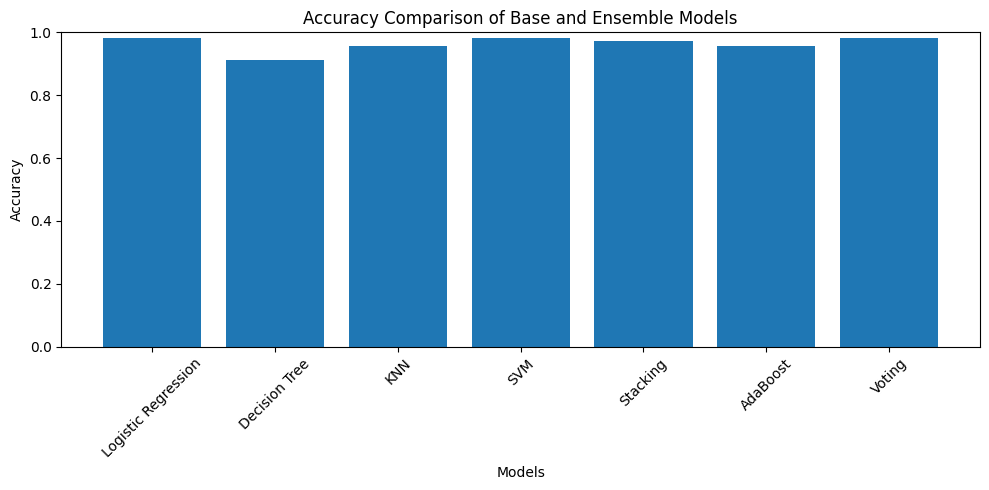

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Base and Ensemble Models")

plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [10]:
print("Best Model Based on Accuracy:")
print(results_df.loc[results_df["Accuracy"].idxmax()])

print("\nBest Model Based on F1 Score:")
print(results_df.loc[results_df["F1 Score"].idxmax()])

Best Model Based on Accuracy:
Model        Logistic Regression
Accuracy                0.982456
Precision               0.986111
Recall                  0.986111
F1 Score                0.986111
Name: 0, dtype: object

Best Model Based on F1 Score:
Model        Logistic Regression
Accuracy                0.982456
Precision               0.986111
Recall                  0.986111
F1 Score                0.986111
Name: 0, dtype: object
